# UCS420 Lab Assignment 9 — NLP Text Preprocessing
**Course:** UCS420: Cognitive Computing  
**Assignment:** Assignment 7 — NLP-I  
**Student Name:** Abhijay Nagal  
**Roll Number:** 1024170013  

In [1]:
ROLL_NO = 1024170013          # <-- your full roll number
NAME = "Abhijay Nagal"        # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"
print(f"Initialized environment for {NAME} (Roll: {ROLL_NO})")

Initialized environment for Abhijay Nagal (Roll: 1024170013)


### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170013   Name: Abhijay Nagal   Fingerprint: 242147B7   Tickets: 15

Ticket_ID                                                                                        Ticket_Text
      T01           E-mail keeps disconnecting after restarting the system. I don't know what changed.
      T02                                                         Email me at helpdesk@university.edu.
      T03  I tried restarting the MATLAB before the assignment deadline. It works on another computer.
      T04                        I can't open the Python while uploading the file. Please resolve it.
      T05                                                            Python 3.12 was installed yesterday.
      T06          I reinstalled the password before the assignment deadline. Can you check this?
      T07            MATLAB crashes while opening after restarting the system. It worked yesterday.
      T08                                    The projector crashes while opening. Please re

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row. For one selected ticket, display the actual tokens, punctuation tokens, stopwords, and final tokens.

In [5]:
# Run process_ticket() on every ticket and build summary table
q1_records = []
processed_data = {}

for _, row in df.iterrows():
    tid = row["Ticket_ID"]
    res = process_ticket(row["Ticket_Text"])
    processed_data[tid] = res
    q1_records.append({
        "Ticket_ID": tid,
        "sentences": len(res["sentences"]),
        "tokens": len(res["tokens"]),
        "punct": len(res["punct"]),
        "stopwords": len(res["stops"]),
        "unique": len(set(res["tokens"])),
        "final": len(res["final"])
    })

q1_df = pd.DataFrame(q1_records)

# Total row for count-based columns
total_row = pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "sentences": q1_df["sentences"].sum(),
    "tokens": q1_df["tokens"].sum(),
    "punct": q1_df["punct"].sum(),
    "stopwords": q1_df["stopwords"].sum(),
    "unique": "-",
    "final": q1_df["final"].sum()
}])
q1_summary = pd.concat([q1_df, total_row], ignore_index=True)
print("=== Ticket Processing Summary Table ===")
print(q1_summary.to_string(index=False))

# Display actual tokens for one selected ticket (FOCUS[0] = T01)
sel_ticket = FOCUS[0]
sel_res = processed_data[sel_ticket]
print(f"\n=== Detailed Token Display for Selected Ticket ({sel_ticket}) ===")
print(f"Ticket Text        : {df[df['Ticket_ID'] == sel_ticket]['Ticket_Text'].values[0]}")
print(f"Actual Tokens ({len(sel_res['tokens'])}) : {sel_res['tokens']}")
print(f"Punctuation ({len(sel_res['punct'])})   : {sel_res['punct']}")
print(f"Stopwords ({len(sel_res['stops'])})     : {sel_res['stops']}")
print(f"Final Tokens ({len(sel_res['final'])})  : {sel_res['final']}")

=== Ticket Processing Summary Table ===
Ticket_ID sentences tokens punct stopwords unique final
      T01         2     15     2         5     14     8
      T02         1      6     2         2      6     2
      T03         2     17     2         8     16     7
      T04         2     14     2         5     14     7
      T05         1      6     1         2      6     3
      T06         2     14     2         6     14     6
      T07         2     13     2         4     12     7
      T08         2     10     2         3     10     5
      T09         2     14     2         5     13     7
      T10         1     11     2         4     11     5
      T11         2     19     2         9     17     8
      T12         2     10     2         4      9     4
      T13         2     17     2         6     15     9
      T14         2     15     2         4     14     9
      T15         2     10     4         2      9     4
    TOTAL        27    191    31        69      -    91

=== Det

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*
In our dataset, the non-standard words appearing in the final tokens are:
1. **`"n't"`**: Originates from contractions such as `"don't"` (T01), `"can't"` (T04), and `"doesn't"` (T10). NLTK's `word_tokenize()` uses the Penn Treebank tokenization standard which isolates negation contractions into the verb stem and `"n't"`. Because `"n't"` is absent from NLTK's standard English stopwords list (`nltk.corpus.stopwords.words("english")`), it survives filtering and enters the final token list.
2. **`"ca"`**: Originates from `"can't"` in T04, which `word_tokenize()` splits into `"ca"` and `"n't"`. While `"can"` is in the stopwords list, the prefix fragment `"ca"` is not recognized as a stopword.
3. **`"3.12"`**: Originates from T05 (`"Python 3.12 was installed yesterday."`). It contains internal digits and a decimal point, meaning `is_punct()` evaluates to `False` (not all characters are punctuation) and it is not a stopword.
4. **`"e-mail"` and `"wi-fi"`**: Hyphenated technical compound terms from T01 and T10/T14 that are preserved intact.
5. **`"university.edu"`**: Originates from the email address `helpdesk@university.edu` in T02. `word_tokenize()` isolates `@` as punctuation, leaving the domain name `university.edu` as a standalone token with an internal dot.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
import re
from collections import Counter

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

raw_tickets_text = " ".join(df["Ticket_Text"].tolist())

# 1. Words longer than 5 letters
words_longer_5 = re.findall(r'\b[a-zA-Z]{6,}\b', raw_tickets_text)
print(f"1. Words longer than 5 letters (Total extracted: {len(words_longer_5)}, Unique: {len(set(words_longer_5))}):")
print(f"   {sorted(list(set(words_longer_5)))}\n")

# 2. Numbers (keeping decimals and version numbers such as 95.5, 2.0.1, 3.12 whole)
numbers_pattern = r'\b\d+(?:\.\d+)*\b'
numbers_in_tickets = re.findall(numbers_pattern, raw_tickets_text)
print(f"2. Numbers in raw tickets (keeping versions/decimals whole):")
print(f"   {numbers_in_tickets}\n")

# 3. Capitalized words
capitalized_words = re.findall(r'\b[A-Z][a-zA-Z]*\b', raw_tickets_text)
print(f"3. Capitalized words (Total: {len(capitalized_words)}):")
print(f"   Frequencies: {dict(Counter(capitalized_words))}\n")

# 4. Words beginning with a vowel
vowel_words = re.findall(r'\b[aeiouAEIOU][a-zA-Z]*\b', raw_tickets_text)
print(f"4. Words beginning with a vowel (Total: {len(vowel_words)}):")
print(f"   Frequencies: {dict(Counter(vowel_words))}\n")

# --- Replacement using re.sub() ---
email_pattern = r'[a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+'
url_pattern = r'https?://[a-zA-Z0-9_./-]+(?<![.,;])|www\.[a-zA-Z0-9_./-]+(?<![.,;])'
phone_pattern = r'\+?\d{1,3}[- ]?\d{5}[- ]?\d{5}|\d{4}-\d{3}-\d{4}'

print("=== Regex Replacement on TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    cleaned = re.sub(email_pattern, '<EMAIL>', line)
    cleaned = re.sub(url_pattern, '<URL>', cleaned)
    cleaned = re.sub(phone_pattern, '<PHONE>', cleaned)
    print(f"Test Line {i} Original: {line}")
    print(f"Test Line {i} Cleaned : {cleaned}\n")

print("=== Regex Replacement on Dataset Tickets ===")
for _, r in df.iterrows():
    t = r["Ticket_Text"]
    subbed = re.sub(email_pattern, '<EMAIL>', t)
    subbed = re.sub(url_pattern, '<URL>', subbed)
    subbed = re.sub(phone_pattern, '<PHONE>', subbed)
    if subbed != t:
        print(f"[{r['Ticket_ID']}] Original: {t}")
        print(f"[{r['Ticket_ID']}] Cleaned : {subbed}")

1. Words longer than 5 letters (Total extracted: 65, Unique: 38):
   ['MATLAB', 'Please', 'Python', 'access', 'another', 'asking', 'assignment', 'before', 'campus', 'cannot', 'changed', 'computer', 'connected', 'crashes', 'deadline', 'disconnecting', 'during', 'failed', 'getting', 'helpdesk', 'installed', 'logged', 'occurs', 'opening', 'password', 'portal', 'problem', 'projector', 'reinstalled', 'resolve', 'restarting', 'student', 'system', 'university', 'uploading', 'urgent', 'worked', 'yesterday']

2. Numbers in raw tickets (keeping versions/decimals whole):
   ['3.12']

3. Capitalized words (Total: 35):
   Frequencies: {'E': 1, 'Email': 1, 'I': 7, 'MATLAB': 3, 'It': 4, 'Python': 2, 'Please': 3, 'Can': 1, 'The': 4, 'Wi': 2, 'Fi': 2, 'VPN': 1, 'This': 1, 'Is': 1, 'Pls': 1, 'ASAP': 1}

4. Words beginning with a vowel (Total: 45):
   Frequencies: {'E': 1, 'Email': 1, 'at': 1, 'university': 1, 'edu': 1, 'I': 7, 'assignment': 2, 'It': 4, 'on': 2, 'another': 2, 'open': 2, 'uploading': 1, '

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*
Across our 15 generated tickets, there are **35 total capitalized word occurrences** across 27 sentences:
- **16 occurrences** (`The`: 4, `It`: 4, `Please`: 3, `Email`: 1, `Can`: 1, `This`: 1, `Is`: 1, `Pls`: 1) are capitalized **solely because they appear in sentence-initial position**. When used elsewhere within sentences, words like *the, it, please, can, this, is* are common English words written in lowercase.
- **7 occurrences** of `"I"` are capitalized because the first-person singular pronoun is orthographically capitalized everywhere in English.
- **12 occurrences** are proper nouns, software names, and acronyms (`MATLAB`: 3, `Python`: 2, `Wi-Fi`: 2, `VPN`: 1, `ASAP`: 1) that remain capitalized regardless of their position in the sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer

custom_pattern = r'''(?x)
    (?:https?://|www\.)[a-zA-Z0-9_./-]+(?<![.,;:])         # URLs (preserving URL, excluding trailing punctuation)
    | [a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+       # Email addresses
    | (?:\+\d{1,3}[- ]?)?\d{5}[- ]?\d{5}|\d{4}-\d{3}-\d{4} # Phone numbers
    | \b\d+(?:\.\d+)+\b                                    # Decimals and versions (95.5, 2.0.1, 5.30, 3.12)
    | \b[A-Za-z]+(?:-[A-Za-z]+)+\b                         # Hyphenated words (Wi-Fi, state-of-the-art, log-in)
    | \b[A-Za-z]+['’][A-Za-z]+\b                           # Contractions (isn't, didn't, don't, can't)
    | \b\d{1,3}(?:,\d{3})+\b                               # Numbers with commas (1,250)
    | \b\w+\b                                              # Standard words and numbers
    | [^\s\w]                                              # Standalone punctuation/symbols
'''

my_tokenizer = RegexpTokenizer(custom_pattern)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

print("=== Comparison on TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    my_toks = my_tokenize(line)
    nltk_toks = word_tokenize(line)
    print(f"\nTest Line {i}: "{line}"")
    print(f"  my_tokenize  : {my_toks}")
    print(f"  word_tokenize: {nltk_toks}")

# Comparison across generated tickets
diff_count = 0
differing_tickets = []
for _, r in df.iterrows():
    txt = r["Ticket_Text"]
    mt = my_tokenize(txt)
    wt = word_tokenize(txt)
    if mt != wt:
        diff_count += 1
        differing_tickets.append(r["Ticket_ID"])

print(f"\n=== Tickets Tokenization Comparison ===")
print(f"Tickets tokenized differently: {diff_count} out of {len(df)} tickets ({differing_tickets})")

=== Comparison on TEST_LINES ===

Test Line 1: "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it."
  my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test Line 2: "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250."
  my_tokenize  : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Test Line 3: "The state

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*
**5 out of 15 tickets** (`T01`, `T02`, `T04`, `T10`, `T14`) are tokenized differently.

### Three Key Differences Explained:
1. **Contractions Handling:**
   - `word_tokenize()` adheres to the Penn Treebank convention and splits contractions into separate tokens (e.g., `"don't"` -> `['do', "n't"]`, `"can't"` -> `['ca', "n't"]`, `"doesn't"` -> `['does', "n't"]`).
   - `my_tokenize()` treats contractions as unified lexical units (`"don't"`, `"can't"`, `"doesn't"`), avoiding artificial word boundary splitting.
2. **Email Addresses and URLs:**
   - `word_tokenize()` splits email addresses and URLs around symbol characters (e.g., `helpdesk@university.edu` is split into `['helpdesk', '@', 'university.edu']` and `https://lms...` into `['https', ':', '//lms...']`).
   - `my_tokenize()` preserves complete web and email identifiers as single distinct tokens.
3. **Multi-word Phone Numbers:**
   - `word_tokenize()` splits spaced telephone numbers (e.g., `+91 98765 43210` -> `['+91', '98765', '43210']`).
   - `my_tokenize()` preserves the full international telephone string `+91 98765 43210` as a single token.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag

# Unique final tokens from the dataset
unique_final_tokens = sorted(list(set([t for res in processed_data.values() for t in res["final"]])))

porter = PorterStemmer()
lancaster = LancasterStemmer()
# Suffix chosen: 'ing$' (min length 4) based on frequent progressive verbs in our tickets:
# 'restarting', 'disconnecting', 'opening', 'asking', 'uploading', 'getting'
regexp_stemmer = RegexpStemmer('ing$', min=4)
wnl = WordNetLemmatizer()

def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN

pos_tags = pos_tag(unique_final_tokens)
q4_diff_rows = []

for word, tag in pos_tags:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word)
    wn_pos = get_wordnet_pos(tag)
    w = wnl.lemmatize(word, wn_pos)
    
    # Table containing ONLY the words for which the outputs differ
    if len({p, l, r, w}) > 1:
        q4_diff_rows.append({
            "Word": word,
            "POS": tag,
            "Porter": p,
            "Lancaster": l,
            "Regexp": r,
            "WordNet_POS": w
        })

q4_table = pd.DataFrame(q4_diff_rows)
print(f"Total unique final tokens: {len(unique_final_tokens)}")
print(f"Tokens with differing outputs: {len(q4_table)}\n")
print(q4_table.to_string(index=False))

Total unique final tokens: 57
Tokens with differing outputs: 33

       Word POS    Porter Lancaster      Regexp WordNet_POS
    another  DT     anoth     anoth     another     another
 assignment  NN    assign    assign  assignment  assignment
     campus  VB     campu      camp      campus      campus
    changed VBD     chang     chang     changed      change
   computer  NN    comput    comput    computer    computer
  connected VBD   connect   connect   connected     connect
    crashes NNS     crash     crash     crashes       crash
   deadline  JJ   deadlin   deadlin    deadline    deadline
     failed VBD      fail      fail      failed        fail
       file  NN      file       fil        file        file
      fixed VBN       fix       fix       fixed         fix
    getting VBG       get       get        gett         get
  installed VBN    instal    instal   installed      instal
      keeps NNS      keep      keep       keeps        keep
     logged VBN       log       log

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
1. **RegexpStemmer Suffix Rule & Justification:**
   - **Suffix Chosen:** `'ing$'` with minimum word length 4.
   - **Justification:** In our generated dataset, progressive verb forms ending with `-ing` are abundant (e.g., `restarting`, `disconnecting`, `opening`, `asking`, `uploading`, `getting`). Stripping `'ing'` cleanly extracts the underlying root verb morpheme (e.g. `restart`, `disconnect`, `open`, `ask`, `upload`) without affecting unrelated short words.

2. **Over-stemming Example:**
   - **`portal` -> `port`** by Lancaster Stemmer (and **`campus` -> `camp`**).
   - *Explanation:* Lancaster aggressively strips the suffix `-al` from `portal`, erroneously reducing it to the root of `port`. A computer/web portal and a maritime or network port are distinct concepts. Conflating them causes false semantic equivalence.

3. **Under-stemming Example:**
   - **`worked`, `installed`, `changed`, `failed`** by RegexpStemmer.
   - *Explanation:* Because RegexpStemmer is bound strictly to the single suffix rule `'ing$'`, it fails to stem past tense inflectional forms ending in `-ed`. Similarly, PorterStemmer under-stems irregular inflections like `tried` -> `tri` instead of resolving to `try`.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

=== Corpus Statistics Table ===
                      Corpus  Total Tokens  Unique Tokens      TTR
              S1: all tokens           191             90 0.471204
S2: tokens without punctuation           160             84 0.525000
            S3: final tokens            91             57 0.626374
S4: S3 after Porter stemming            91             54 0.593407

=== Top 10 Words ===
Top 10 words in S1:
             .: 24
           the: 19
            it: 8
             i: 7
    restarting: 5
         after: 3
        system: 3
           n't: 3
        matlab: 3
         works: 3

Top 10 words in S3:
    restarting: 5
        system: 3
           n't: 3
        matlab: 3
         works: 3
        please: 3
       resolve: 3
     yesterday: 3
         keeps: 2
         tried: 2

=== Top 5 Bigrams ===
Top 5 bigrams in S1:
                ('.', 'i'): 7
     ('restarting', 'the'): 5
               ('.', 'it'): 4
              ('.', 'the'): 4
   ('after', 'restarting'): 3

Top 5 bigra

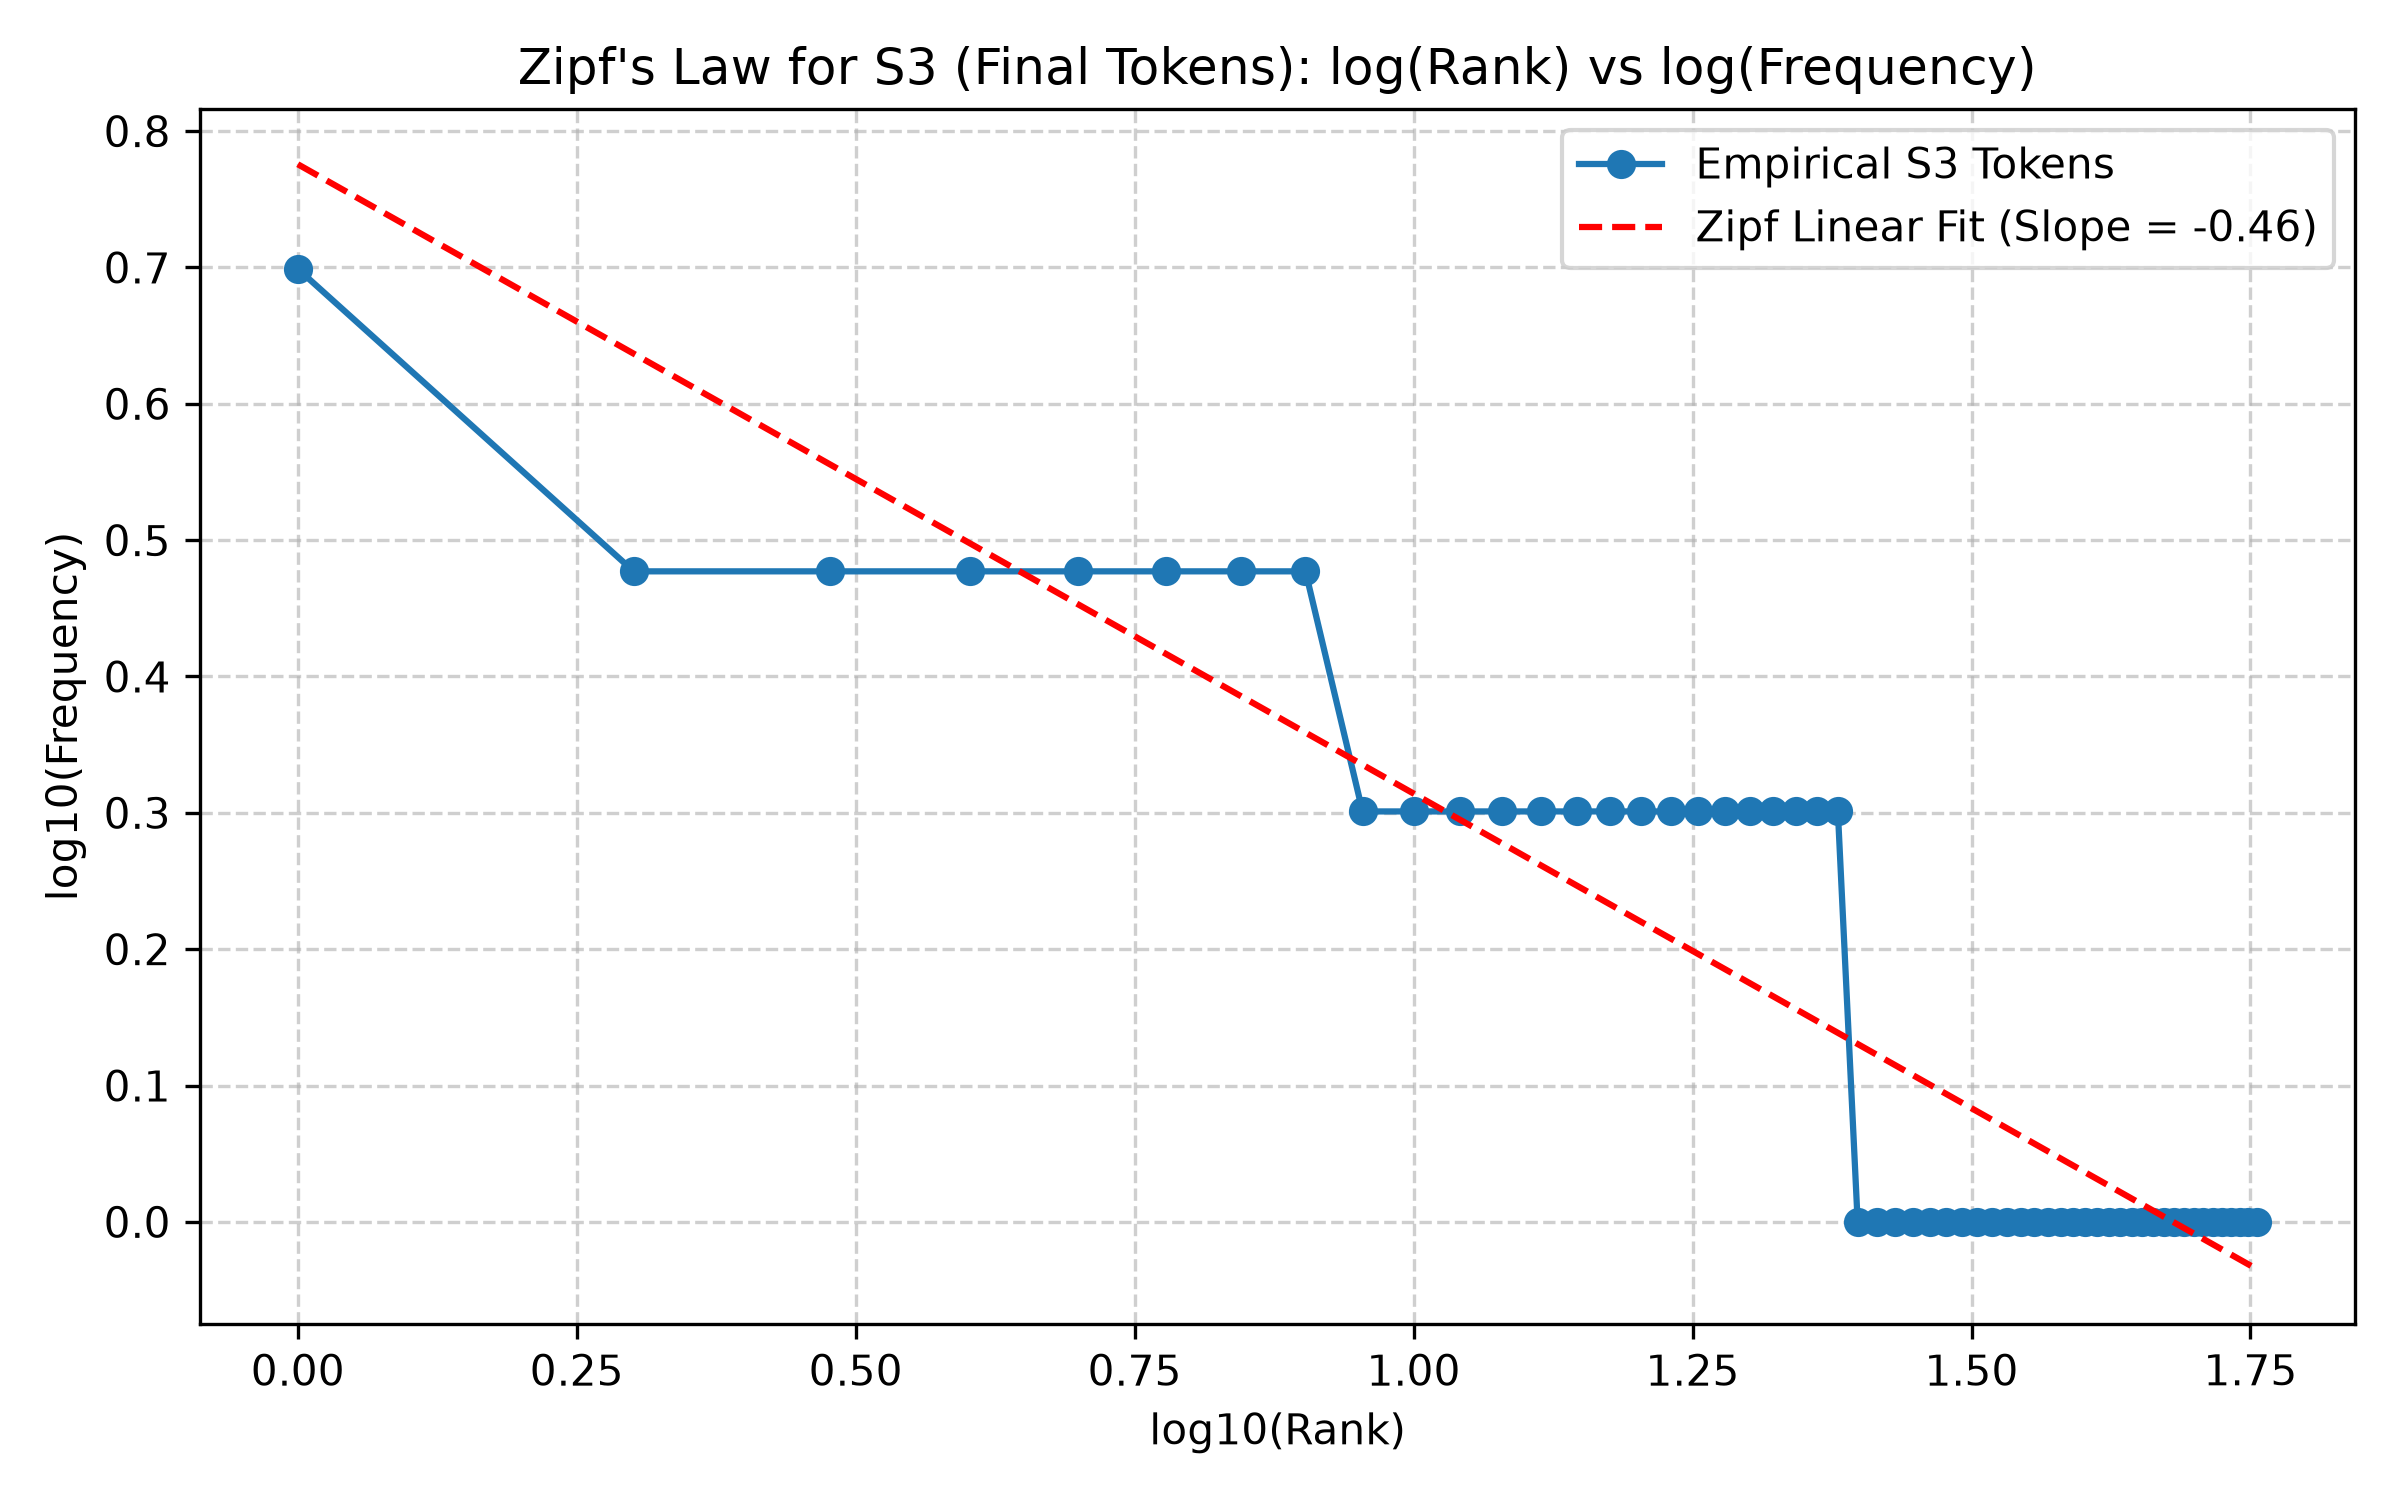

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# S1: all tokens
s1 = [t for res in processed_data.values() for t in res["tokens"]]
# S2: tokens without punctuation
s2 = [t for res in processed_data.values() for t in res["tokens"] if not is_punct(t)]
# S3: final tokens
s3 = [t for res in processed_data.values() for t in res["final"]]
# S4: S3 after Porter stemming
s4 = [porter.stem(t) for t in s3]

def calc_stats(t_list):
    total = len(t_list)
    unique = len(set(t_list))
    ttr = unique / total if total > 0 else 0
    return total, unique, ttr

stats_summary = pd.DataFrame({
    "Corpus": ["S1: all tokens", "S2: tokens without punctuation", "S3: final tokens", "S4: S3 after Porter stemming"],
    "Total Tokens": [calc_stats(s1)[0], calc_stats(s2)[0], calc_stats(s3)[0], calc_stats(s4)[0]],
    "Unique Tokens": [calc_stats(s1)[1], calc_stats(s2)[1], calc_stats(s3)[1], calc_stats(s4)[1]],
    "TTR": [calc_stats(s1)[2], calc_stats(s2)[2], calc_stats(s3)[2], calc_stats(s4)[2]]
})
print("=== Corpus Statistics Table ===")
print(stats_summary.to_string(index=False))

print("\n=== Top 10 Words ===")
print("Top 10 words in S1:")
for w, cnt in Counter(s1).most_common(10):
    print(f"  {w:>12}: {cnt}")

print("\nTop 10 words in S3:")
for w, cnt in Counter(s3).most_common(10):
    print(f"  {w:>12}: {cnt}")

print("\n=== Top 5 Bigrams ===")
print("Top 5 bigrams in S1:")
for bg, cnt in Counter(list(nltk.bigrams(s1))).most_common(5):
    print(f"  {str(bg):>24}: {cnt}")

print("\nTop 5 bigrams in S3:")
for bg, cnt in Counter(list(nltk.bigrams(s3))).most_common(5):
    print(f"  {str(bg):>24}: {cnt}")

# Plot log(rank) vs log(frequency) for S3
s3_counts = Counter(s3)
sorted_freqs = sorted(s3_counts.values(), reverse=True)
ranks = np.arange(1, len(sorted_freqs) + 1)
freqs = np.array(sorted_freqs)

log_ranks = np.log10(ranks)
log_freqs = np.log10(freqs)

slope, intercept = np.polyfit(log_ranks, log_freqs, 1)

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_freqs, marker='o', linestyle='-', color='#1f77b4', label='Empirical S3 tokens')
plt.plot(log_ranks, slope * log_ranks + intercept, 'r--', label=f'Zipf Linear Fit (Slope = {slope:.2f})')
plt.title("Zipf's Law for S3: log(Rank) vs log(Frequency)")
plt.xlabel("log10(Rank)")
plt.ylabel("log10(Frequency)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*
The Type-Token Ratio (TTR = $\frac{\text{Unique Tokens}}{\text{Total Tokens}}$) quantifies lexical diversity:
1. **S1 (TTR = 0.4712):** Baseline raw tokens containing repetitive punctuation marks (e.g. 24 periods) and high-frequency functional stopwords (`the`, `it`, `i`). The large denominator of repeated tokens suppresses TTR.
2. **S2 (TTR = 0.5250):** Removing punctuation reduces the total token count by 31 while removing only 6 unique punctuation symbols, causing TTR to increase.
3. **S3 (TTR = 0.6264):** Removing stopwords eliminates high-frequency, non-content grammatical particles (`the`, `it`, `after`, etc.). This causes a major drop in total tokens (160 -> 91) while preserving content words, peaking TTR at its highest diversity.
4. **S4 (TTR = 0.5934):** Applying Porter stemming collapses morphological variants of the same root word (e.g., `works` and `worked` -> `work`, `keeps` -> `keep`) into shared stems. This reduces the number of unique types (from 57 to 54) while total tokens remain unchanged (91), thereby decreasing TTR.

---
## 6. Interpretation
**Brief Answers to the Questions:**

**(a) Why does TTR change from S1 to S4 in your dataset?**  
- **S1 to S2:** Increases from 0.4712 to 0.5250 because repetitive punctuation tokens (like `.` which appears 24 times) are removed, reducing total tokens faster than unique types.  
- **S2 to S3:** Rises sharply to 0.6264 because common stopwords (e.g. `the`, `it`, `i`) are filtered out. Since stopwords are heavily repeated, removing them significantly shrinks total tokens while retaining distinctive vocabulary.  
- **S3 to S4:** Decreases from 0.6264 to 0.5934 because stemming conflates inflectional variants (e.g., `works` and `worked` both map to `work`), reducing vocabulary size (unique types) while the total number of tokens remains 91.

**(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.**  
- **Example:** `"The Wi-Fi works, but the VPN doesn't."` and `"Email me at helpdesk@university.edu."`  
- **Difference:** `word_tokenize()` breaks `"doesn't"` into `['does', "n't"]` and `"helpdesk@university.edu"` into `['helpdesk', '@', 'university.edu']`. In contrast, `my_tokenize()` preserves `"doesn't"` as a single contraction token and keeps `"helpdesk@university.edu"` unified as an email token, preventing artificial fragmentation of domain entities and compound predicates.

**(c) Give one example where stemming produces an undesirable result.**  
- **Example:** Lancaster Stemmer stems `"portal"` to `"port"` and `"campus"` to `"camp"`.  
- **Explanation:** This is an over-stemming failure: Lancaster strips valid morphemic parts (`-al`, `-us`), conflating a software user portal with a hardware port / harbor, and an educational campus with a campsite, entirely distorting their semantics.

**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**  
- **Example:** The word `"opening"` (`POS = NN`, noun) in `"MATLAB crashes while opening"`.  
- **Explanation:** Porter stemmer blindly chops suffixes, converting `"opening"` into the verb stem `"open"`. In contrast, WordNet lemmatizer using POS tag `NOUN` correctly retains `"opening"` as a distinct grammatical noun describing the event/action, avoiding loss of grammatical category and meaning. For past tense verb `"changed"`, WordNet lemmatizer maps it to standard dictionary root `"change"`, whereas Porter truncates it to the non-word stem `"chang"`.